In [1]:
#Install the required libraries
%pip install pandas 
%pip install numpy 
%pip install matplotlib 
%pip install seaborn 
%pip install scikit-learn 
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


...


[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [3]:
#Loading dataset
df=pd.read_excel("Online Retail.xlsx")

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
#checking the missing values
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
#View basic statistics
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


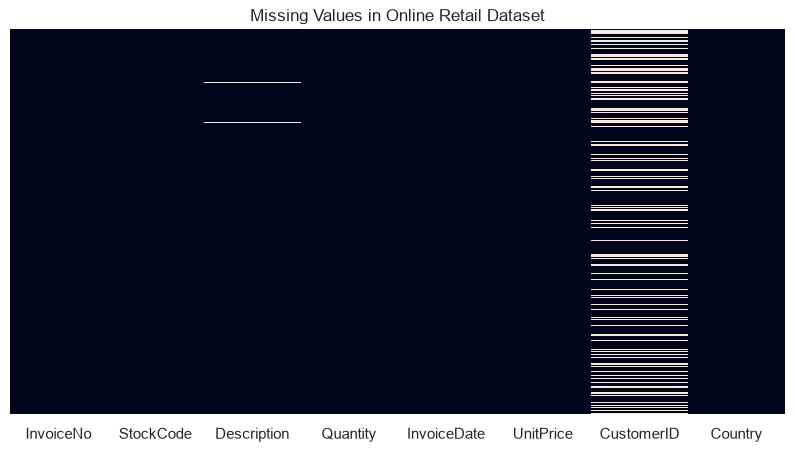

In [7]:
#Visualize missing customer IDs
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(),cbar=False,yticklabels=False)
plt.title("Missing Values in Online Retail Dataset")
plt.show()

In [8]:
#cleaning
df_clean = df.dropna(subset=["CustomerID"]).copy()

df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

df_clean = df_clean[(~df_clean["InvoiceNo"].str.startswith("C")) &(df_clean["Quantity"] > 0) &(df_clean["UnitPrice"] > 0)].copy()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

df_clean["Revenue"] = (df_clean["Quantity"] * df_clean["UnitPrice"])

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())

df_clean.head()

Original records: 541909
Cleaned records: 397884
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


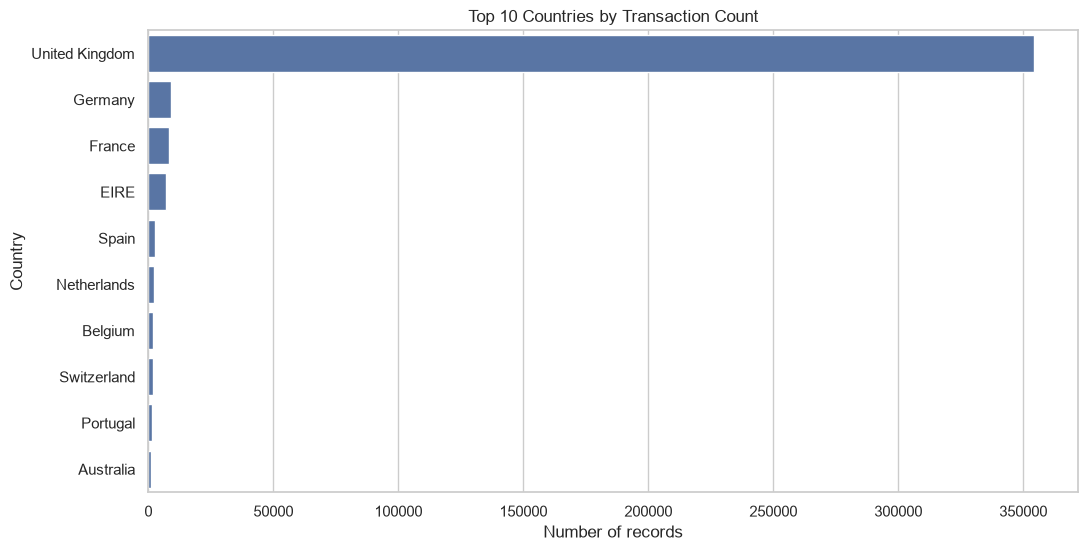

In [9]:
#Perform exploratory data analysis
country_counts = df_clean["Country"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries by Transaction Count")
plt.xlabel("Number of records")
plt.ylabel("Country")
plt.show()

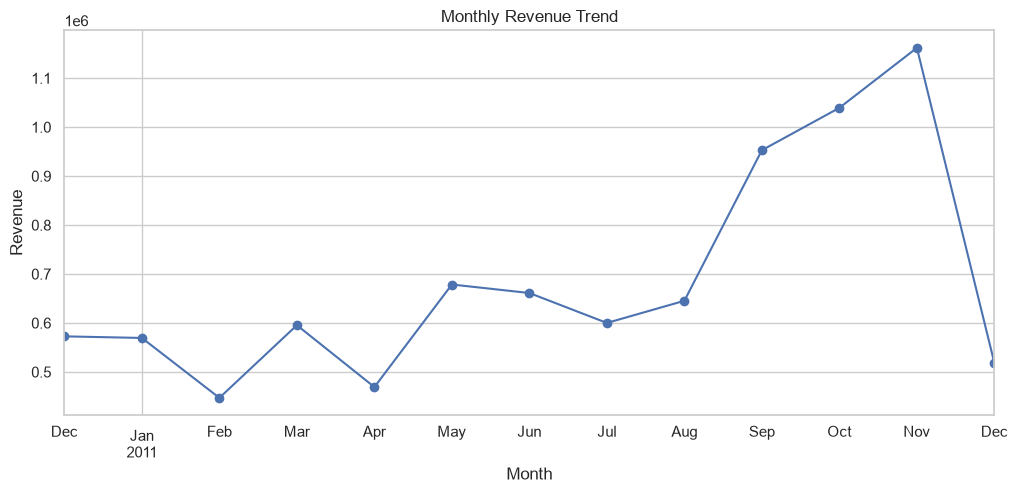

In [10]:
#Monthly revenue trend
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

monthly_revenue = (df_clean.set_index("InvoiceDate")["Revenue"].resample("ME").sum())

plt.figure(figsize=(12, 5))
monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [11]:
#RFM features
snapshot_date = (df_clean["InvoiceDate"].max() + pd.Timedelta(days=1))

rfm = df_clean.groupby("CustomerID").agg(Recency=("InvoiceDate",lambda x: (snapshot_date - x.max()).days),Frequency=("InvoiceNo", "nunique"),Monetary=("Revenue", "sum"))

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [12]:
#Inspect the resulting dataset
print("Number of customers:", len(rfm))
rfm.describe()

Number of customers: 4338


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [13]:
#Scale the features
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


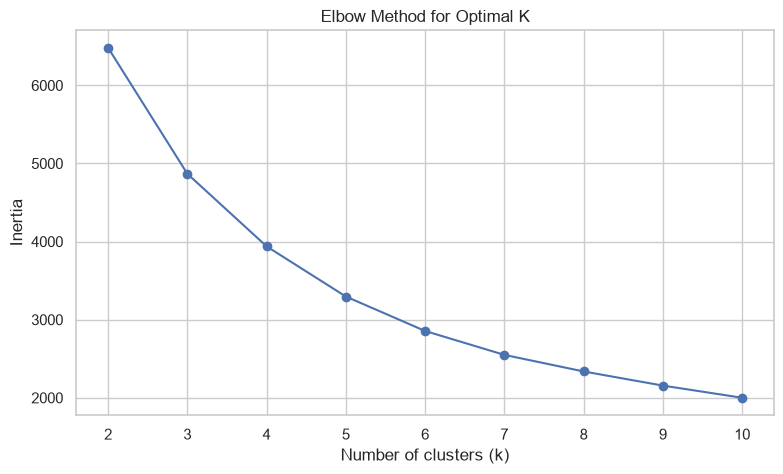

In [14]:
#Find the optimal number of clusters
inertia = []

for k in range(2, 11):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.show()

In [15]:
#calculating silhouette scores
for k in range(2, 8):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled,labels,sample_size=min(5000, len(X_scaled)),random_state=42)

    print(f"k = {k}, Silhouette Score = {score:.3f}")

k = 2, Silhouette Score = 0.433
k = 3, Silhouette Score = 0.337
k = 4, Silhouette Score = 0.337
k = 5, Silhouette Score = 0.316
k = 6, Silhouette Score = 0.313
k = 7, Silhouette Score = 0.310


In [16]:
#Training the final model
kmeans = KMeans(n_clusters=4,random_state=42,n_init=10)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,2
12347,2,7,4310.00,1
12348,75,4,1797.24,2
12349,19,1,1757.55,0
12350,310,1,334.40,3
